# 1.11. Generate montage for illustrating the PedCP90Sim degradation dataset

PedCP90Sim "augments" real Cell Painting fluorescence patches using controlled image degradations to yield paired ground truth and degradation variants. 

This notebook selects one saved patch from an editable biological context and displays its reference alongside every configured degradation family and severity level. 

In [1]:
from pathlib import Path

import lance
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from utils.encoding import decode_pixel_record
from utils.validate_config import load_yaml_config, require_config_directory

In [2]:
# Helpers: SQL-safe selection, key-based loading, and calibrated annotation.
def sql_string(value):
    """Quote a metadata value for a Lance SQL filter."""
    return "'" + str(value).replace("'", "''") + "'"


def read_one_record(dataset, record_id):
    """Load exactly one record by key without decoding the rest of the dataset."""
    records = dataset.scanner(
        filter=f"record_id = {sql_string(record_id)}",
        batch_size=1,
        batch_readahead=1,
        fragment_readahead=1,
    ).head(2).to_pylist()
    if len(records) != 1:
        raise ValueError(f"Expected exactly one record for {record_id!r}; found {len(records)}.")
    return records[0]


def add_scale_bar(ax, image_shape, pixel_res, length_um=30):
    """Draw a calibrated white bar; pixel_res is in micrometers per pixel."""
    height, width = image_shape
    if pixel_res <= 0 or length_um <= 0:
        raise ValueError("Scale-bar length and pixel resolution must be positive.")
    length_px = length_um / pixel_res
    if length_px > 0.8 * width:
        raise ValueError("Scale bar must fit within the image.")
    bar_x = width * 0.92 - length_px
    bar_y = height * 0.90
    ax.add_patch(plt.Rectangle(
        (bar_x, bar_y), length_px, max(2, height * 0.015), color="white"
    ))
    ax.text(
        bar_x + length_px / 2, bar_y - height * 0.025, f"{length_um:g} µm",
        color="white", fontsize=7, ha="center", va="bottom",
    )

## Paths, catalog, and editable settings

In [3]:
# Support execution from either this notebook's directory or the repository root.
notebook_dir = Path.cwd()
if not (notebook_dir / "degradation_config.yaml").is_file():
    notebook_dir = notebook_dir / "1.image_degradation_simulation"
config = load_yaml_config(notebook_dir / "degradation_config.yaml")
analysis_dir = require_config_directory(config, "analysis_out_dir")
reference_uri = analysis_dir / "patches" / "reference_records" / "data.lance"
degraded_uri = analysis_dir / "patches" / "degraded_records" / "data.lance"
catalog_path = analysis_dir / "degradation_catalog.csv"
metadata_dir = notebook_dir / "metadata"

for path in (reference_uri, degraded_uri, catalog_path):
    if not path.exists():
        raise FileNotFoundError(f"Required input missing: {path}. Run notebooks 1.2–1.3 first.")

degradation_catalog = pd.read_csv(catalog_path, float_precision="round_trip").sort_values("page_index")
required_columns = {
    "page_index", "transform_name", "transform_level", "parameter_name", "parameter_value"
}
if not required_columns.issubset(degradation_catalog.columns):
    raise ValueError(f"Catalog must contain {sorted(required_columns)}.")
if degradation_catalog.empty or degradation_catalog["page_index"].tolist() != list(
    range(len(degradation_catalog))
):
    raise ValueError("Catalog page indexes must be unique and contiguous, starting at zero.")
if degradation_catalog.duplicated(["transform_name", "transform_level"]).any():
    raise ValueError("Catalog contains duplicate transform/level combinations.")

# Editable biological context and plotting settings.
cell_line = "U2-OS"
seeding_density = 2000  # Set to None to allow any density.
platemap_file = "Assay_Plate1_platemap"  # Set to None to allow either platemap.
channel = "OrigER"
seed = 0
pixel_res_um = 0.59337626
scale_bar_um = 30
intensity_scaling = "reference"  # "reference" or "dynamic"
save_figure = True
output_dir = notebook_dir / "results" / "degradation_montage"

reference_dataset = lance.dataset(reference_uri)
degraded_dataset = lance.dataset(degraded_uri)
display(degradation_catalog)

,page_index,transform_name,transform_level,parameter_name,parameter_value,albumentations_function,opencv_function,parameters_json,albumentations_version,opencv_version
0,0,grid_distortion,1,distort_limit,0.100000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-0.1,0.1],""interpolation"":1,...",2.0.1,4.10.0
1,1,grid_distortion,2,distort_limit,0.200000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-0.2,0.2],""interpolation"":1,...",2.0.1,4.10.0
2,2,grid_distortion,3,distort_limit,0.400000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-0.4,0.4],""interpolation"":1,...",2.0.1,4.10.0
3,3,grid_distortion,4,distort_limit,0.600000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-0.6,0.6],""interpolation"":1,...",2.0.1,4.10.0
4,4,grid_distortion,5,distort_limit,0.800000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-0.8,0.8],""interpolation"":1,...",2.0.1,4.10.0
5,5,grid_distortion,6,distort_limit,1.000000,albumentations.GridDistortion,cv2.remap,"{""distort_limit"":[-1.0,1.0],""interpolation"":1,...",2.0.1,4.10.0
6,6,gauss_noise,1,std_range,0.010000,albumentations.GaussNoise,NaN,"{""mean_range"":[0.0,0.0],""noise_scale_factor"":1...",2.0.1,4.10.0
7,7,gauss_noise,2,std_range,0.020000,albumentations.GaussNoise,NaN,"{""mean_range"":[0.0,0.0],""noise_scale_factor"":1...",2.0.1,4.10.0
8,8,gauss_noise,3,std_range,0.030000,albumentations.GaussNoise,NaN,"{""mean_range"":[0.0,0.0],""noise_scale_factor"":1...",2.0.1,4.10.0
9,9,gauss_noise,4,std_range,0.040000,albumentations.GaussNoise,NaN,"{""mean_range"":[0.0,0.0],""noise_scale_factor"":1...",2.0.1,4.10.0


## Select and load one matched example

Filter plate/well metadata by the requested context, sample a saved stack reproducibly, then load its reference by `record_id`. Inspect the selected metadata and verify shared provenance and image dimensions before interpreting the montage.

In [4]:
# Join barcode and platemap metadata to identify the requested biological context.
barcode_df = pd.read_csv(metadata_dir / "Barcode_platemap_pilot_data.csv").rename(
    columns={"barcode": "Metadata_Plate"}
)
platemaps = pd.concat(
    [
        pd.read_csv(metadata_dir / "platemaps" / f"{name}.csv").assign(platemap_file=name)
        for name in barcode_df["platemap_file"].unique()
    ],
    ignore_index=True,
)
biological_metadata = barcode_df.merge(
    platemaps, on="platemap_file", how="inner"
).rename(columns={"well": "Metadata_Well"})
matching_wells = biological_metadata.loc[biological_metadata["cell_line"] == cell_line]
if seeding_density is not None:
    matching_wells = matching_wells.loc[matching_wells["seeding_density"] == seeding_density]
if platemap_file is not None:
    matching_wells = matching_wells.loc[matching_wells["platemap_file"] == platemap_file]
matching_wells = matching_wells.drop_duplicates(["Metadata_Plate", "Metadata_Well"])
if matching_wells.empty:
    raise ValueError("No plate/well metadata match the selected biological context.")

well_clauses = [
    f"(Metadata_Plate = {sql_string(plate)} AND Metadata_Well = {sql_string(well)})"
    for plate, well in matching_wells[["Metadata_Plate", "Metadata_Well"]].itertuples(
        index=False, name=None
    )
]
row_filter = f"channel = {sql_string(channel)} AND (" + " OR ".join(well_clauses) + ")"
# Scan identifying columns only, not the potentially large stack pixel buffers.
candidate_metadata = degraded_dataset.to_table(
    columns=["record_id", "Metadata_Plate", "Metadata_Well", "Metadata_Site"],
    filter=row_filter,
).to_pandas()
if candidate_metadata.empty:
    raise ValueError(f"No saved {channel} degradation stacks match the selected context.")
candidates = candidate_metadata.merge(
    matching_wells, on=["Metadata_Plate", "Metadata_Well"], how="left", validate="many_to_one"
).sort_values("record_id")
# Stable candidate order and a fixed seed make the selected example reproducible.
selected_metadata = candidates.sample(n=1, random_state=seed).iloc[0]
selected_record_id = str(selected_metadata["record_id"])
print(f"Selected one of {len(candidates):,} matching saved stacks (seed={seed}).")
display(selected_metadata.to_frame("selected sample"))

Selected one of 200 matching saved stacks (seed=0).


,selected sample
record_id,000007621:OrigER
Metadata_Plate,BR00143976
Metadata_Well,M15
Metadata_Site,4
time_point,24
platemap_file,Assay_Plate1_platemap
cell_line,U2-OS
row,M
column,15
seeding_density,2000


In [5]:
# Match by key rather than mirrored fragments: reference data may have been regenerated.
reference_image, reference_metadata = decode_pixel_record(
    read_one_record(reference_dataset, selected_record_id), expected_axes="YX"
)
degraded_stack, degradation_metadata = decode_pixel_record(
    read_one_record(degraded_dataset, selected_record_id), expected_axes="SYX"
)
# Shared provenance includes plate/well/site, channel, source paths and crop geometry.
for key in reference_metadata.keys() & degradation_metadata.keys():
    if reference_metadata[key] != degradation_metadata[key]:
        raise ValueError(f"Reference/stack provenance differs for {key!r}; check regenerated records.")
# Confirm the catalog represents the same specifications as the stored stack.
from utils.degrade_spec import build_degradation_specs, specs_to_frame
from utils.write_degrade_image import _fingerprint_degradation_specs

degradation_specs = build_degradation_specs()
expected_catalog = specs_to_frame(degradation_specs).drop(
    columns=["albumentations_version", "opencv_version"]
)
pd.testing.assert_frame_equal(
    degradation_catalog[expected_catalog.columns].reset_index(drop=True).fillna(""),
    expected_catalog, check_dtype=False, check_exact=True,
)
if degradation_metadata.get("spec_fingerprint") != _fingerprint_degradation_specs(degradation_specs):
    raise ValueError("Degraded record specifications differ from the catalog; regenerate matched inputs.")
if degraded_stack.shape != (len(degradation_catalog), *reference_image.shape):
    raise ValueError(
        f"Stack shape {degraded_stack.shape} disagrees with the catalog/reference "
        f"({len(degradation_catalog)} pages, reference shape {reference_image.shape})."
    )
if not np.isfinite(reference_image).all() or not np.isfinite(degraded_stack).all():
    raise ValueError("Selected images contain non-finite pixels.")

display(pd.Series({
    "record_id": selected_record_id,
    "reference_shape": reference_image.shape,
    "stack_shape": degraded_stack.shape,
    "degradation_families": degradation_catalog["transform_name"].nunique(),
    "saved_stack_MiB": degraded_stack.nbytes / 1024**2,
}, name="loaded sample"))

/home/weishanli/anaconda3/envs/vs-metric-analysis/lib/python3.12/site-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.1'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


record_id               000007621:OrigER
reference_shape               (256, 256)
stack_shape               (36, 256, 256)
degradation_families                   6
saved_stack_MiB                      9.0
Name: loaded sample, dtype: object

## Render and export the dataset preview

Use catalog page indexes to place each stored variant in the correct row and column. The reference is repeated to make within-family comparisons easy; one calibrated scale bar applies to all panels. Saved filenames include the selected record and scaling mode.

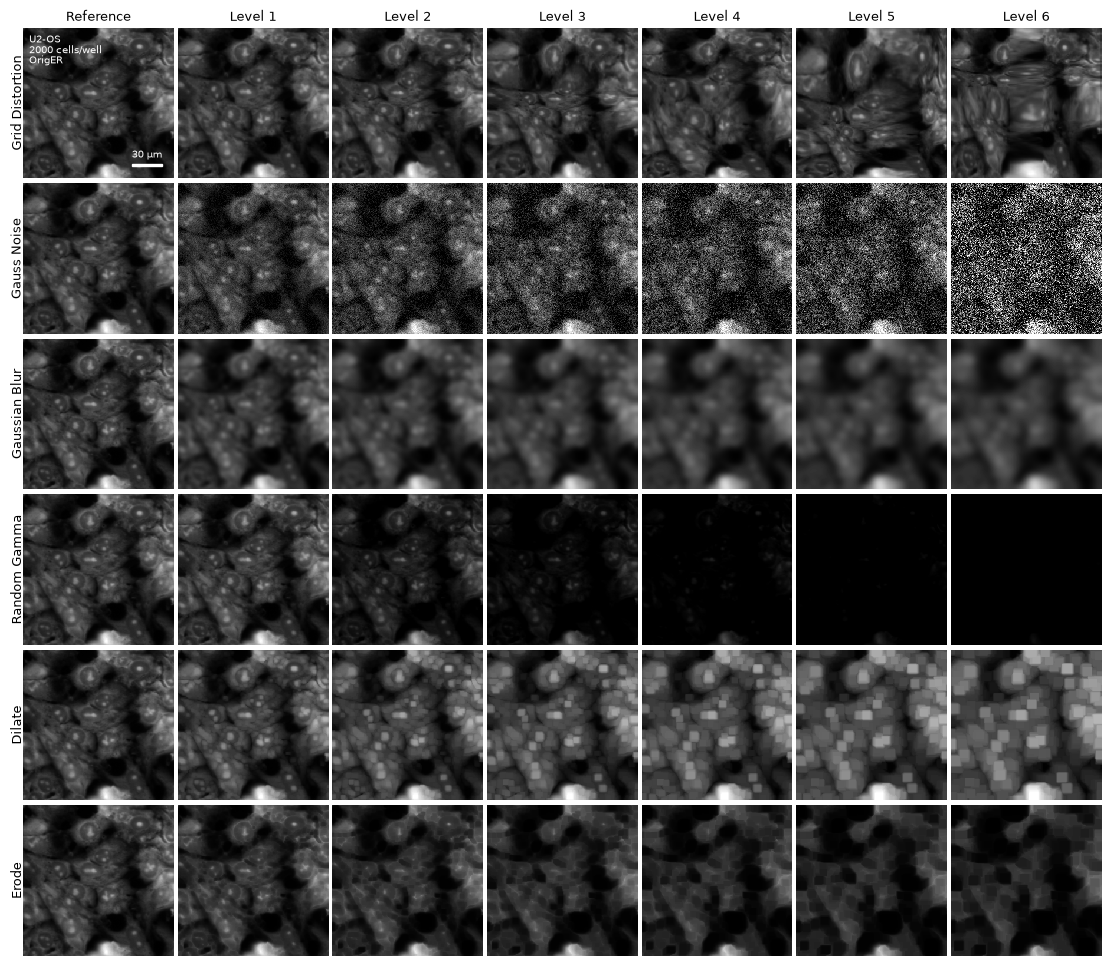

In [7]:
# Reference scaling preserves intensity differences; dynamic scaling is per panel.
if intensity_scaling not in {"reference", "dynamic"}:
    raise ValueError("intensity_scaling must be 'reference' or 'dynamic'.")
if intensity_scaling == "reference":
    vmin, vmax = float(reference_image.min()), float(reference_image.max())
    if np.isclose(vmin, vmax):
        tolerance = max(abs(vmin) * 1e-6, 1e-6)
        vmin, vmax = vmin - tolerance, vmax + tolerance
    image_kwargs = {"vmin": vmin, "vmax": vmax}
else:
    image_kwargs = {}

transform_names = degradation_catalog["transform_name"].drop_duplicates().tolist()
levels = sorted(degradation_catalog["transform_level"].unique())
nrows, ncols = len(transform_names), len(levels) + 1
# Match the figure's grid aspect to the images so gutters remain equally narrow.
image_aspect = reference_image.shape[0] / reference_image.shape[1]
fig, axes = plt.subplots(
    nrows, ncols, figsize=(1.6 * ncols, 1.6 * nrows * image_aspect),
    squeeze=False, gridspec_kw={"wspace": 0.025, "hspace": 0.025},
)
fig.subplots_adjust(left=0.035, right=0.998, bottom=0.002, top=0.97)
for ax in axes.flat:
    ax.axis("off")

for row, transform_name in enumerate(transform_names):
    axes[row, 0].imshow(reference_image, cmap="gray", interpolation="nearest", **image_kwargs)
    axes[row, 0].text(
        -0.04, 0.5, transform_name.replace("_", " ").title(),
        transform=axes[row, 0].transAxes, ha="center", va="center",
        rotation=90, fontsize=9,
    )
    family = degradation_catalog.loc[degradation_catalog["transform_name"] == transform_name]
    for entry in family.itertuples(index=False):
        col = levels.index(entry.transform_level) + 1
        axes[row, col].imshow(
            degraded_stack[int(entry.page_index)],
            cmap="gray", interpolation="nearest", **image_kwargs,
        )

# One slim header row; no per-panel parameter labels or figure captions.
for col, label in enumerate(["Reference", *[f"Level {level}" for level in levels]]):
    axes[0, col].text(
        0.5, 1.025, label, transform=axes[0, col].transAxes,
        ha="center", va="bottom", fontsize=9,
    )
axes[0, 0].text(
    0.04, 0.96,
    f"{selected_metadata['cell_line']}\n"
    f"{selected_metadata['seeding_density']:g} cells/well\n{channel}",
    transform=axes[0, 0].transAxes, ha="left", va="top",
    color="white", fontsize=7, linespacing=1.1,
)
add_scale_bar(axes[0, 0], reference_image.shape, pixel_res_um, scale_bar_um)

if save_figure:
    output_dir.mkdir(parents=True, exist_ok=True)
    output_stem = (
        f"{cell_line}_{channel}_{selected_record_id.replace(':', '_')}_{intensity_scaling}"
    )
    for extension in ("png", "pdf"):
        fig.savefig(
            output_dir / f"{output_stem}.{extension}",
            dpi=200, bbox_inches="tight", pad_inches=0.02,
        )
plt.show()